<a href="https://colab.research.google.com/github/ynsdev1453/Self-Balancing-Robot/blob/main/Fourier_opdracht.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

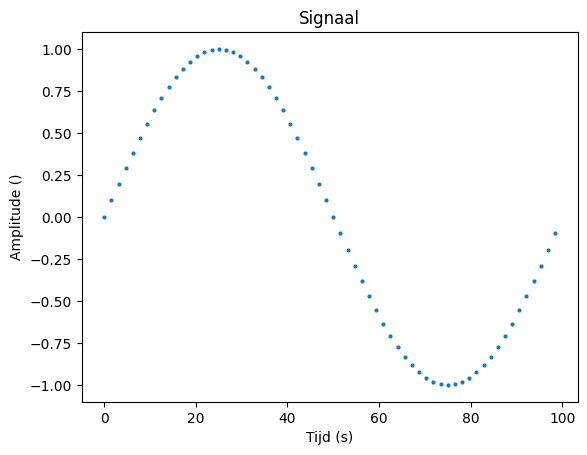

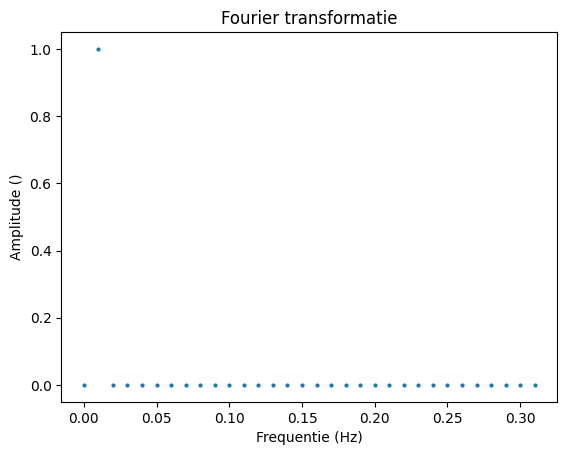

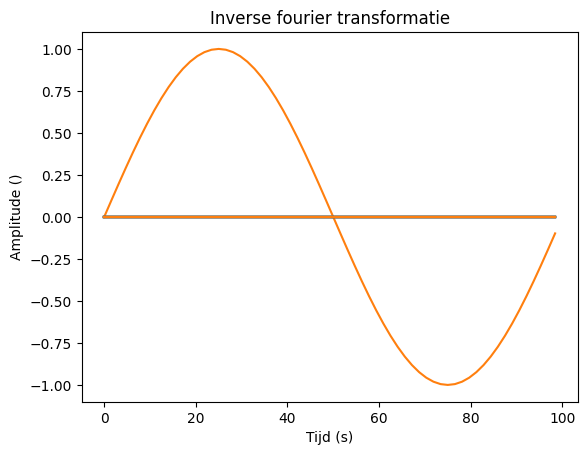

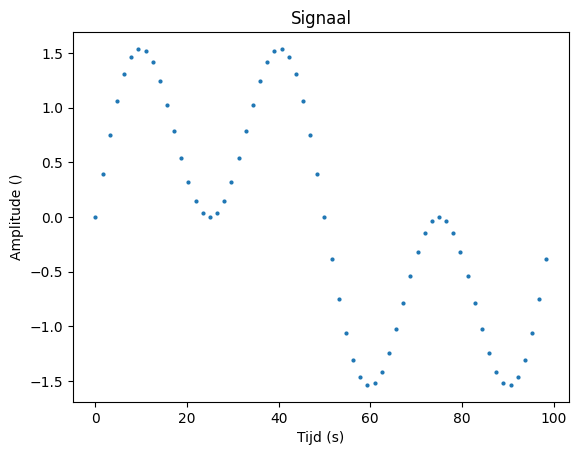

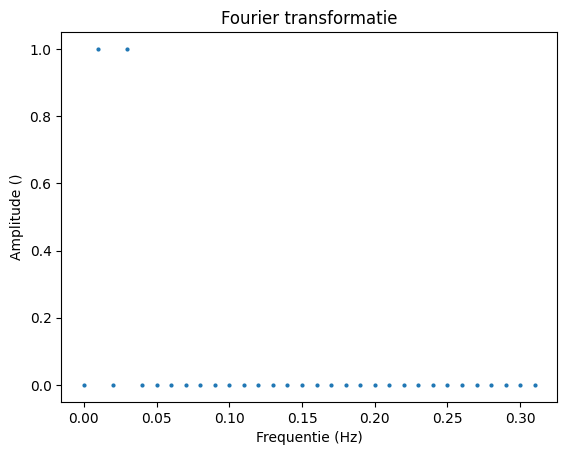

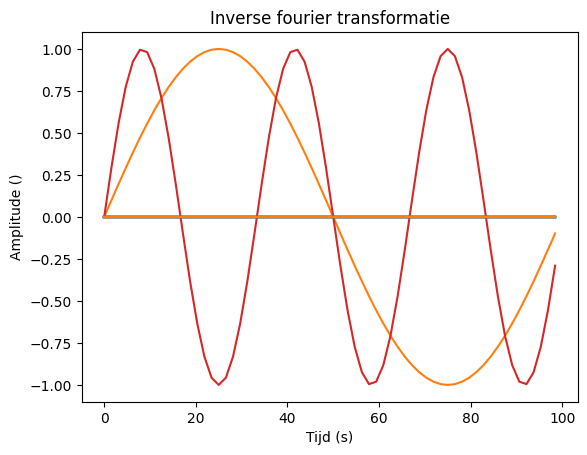

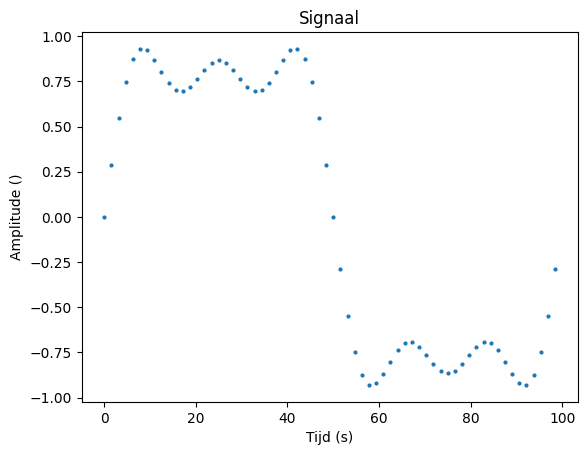

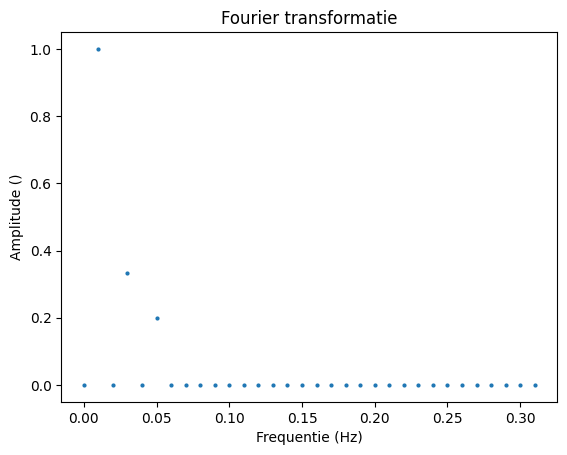

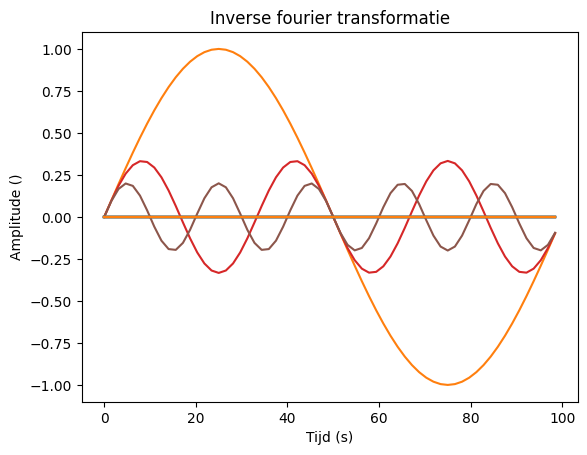

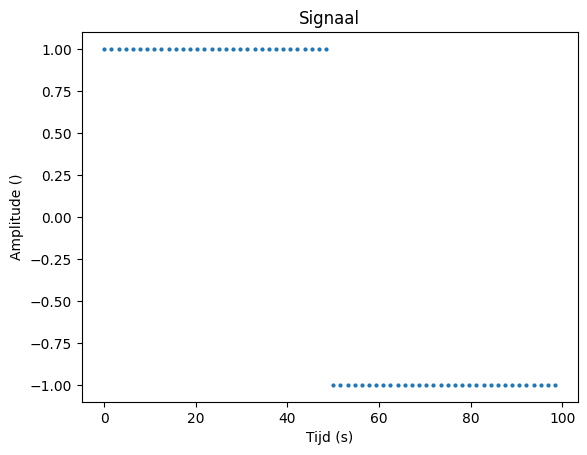

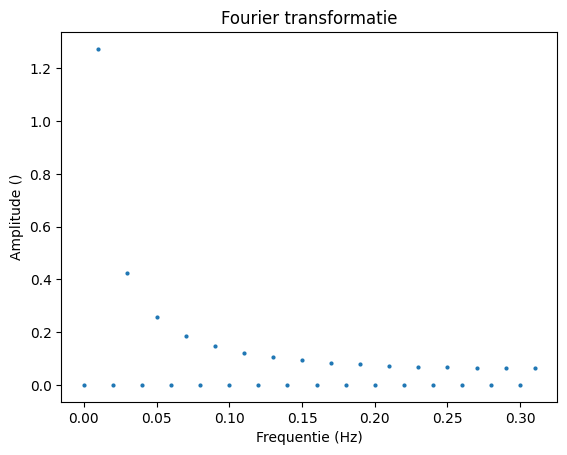

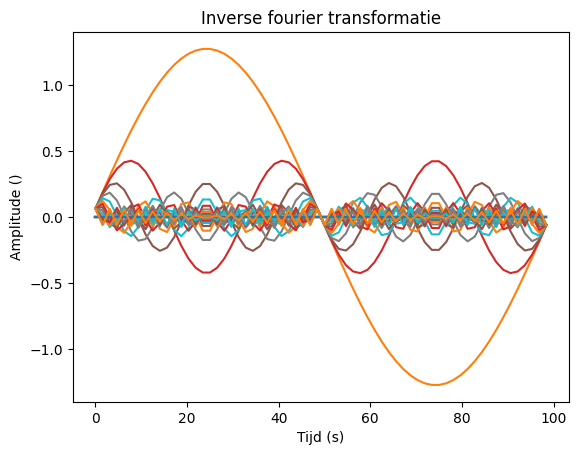

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

maxarray=64
signaal =np.zeros((maxarray),dtype=float)
t=np.zeros((maxarray),dtype=float)
dt=1/0.64    # 1 sec


def DFT():
    for i in range (len(t)):
        t[i]=i*dt
    sinus=np.zeros((int(maxarray/2)),dtype=float)
    cosinus=np.zeros((int(maxarray/2)),dtype=float)
    ifft =np.zeros((maxarray),dtype=float)
    mag=np.zeros((int(maxarray/2)),dtype=float)
    f=np.zeros((int(maxarray/2)),dtype=float)
    for i in range(len(f)) :
        f[i]=i*1/(dt*maxarray)
    for k in range (int(maxarray/2)):
        for i in range (len(t)):
            sinus[k]+=signaal[i]*np.sin(2*k*i*np.pi/len(t))/(maxarray/2)
            cosinus[k]+=signaal[i]*np.cos(2*np.pi*k*i/len(t))/(maxarray/2)
    cosinus[0]=cosinus[0]*0.5
    for k in range (int(maxarray/2)):
        mag[k]=(sinus[k]**2+cosinus[k]**2)**0.5
    fig,ax= plt.subplots()
    plt.scatter(t,signaal,s=4)
    plt.title ('Signaal')
    plt.xlabel('Tijd (s)')
    plt.ylabel('Amplitude ()')
    plt.show()
    plt.scatter(f,mag,s=4)
    plt.title ('Fourier transformatie')
    plt.xlabel('Frequentie (Hz)')
    plt.ylabel('Amplitude ()')
    plt.show()
    for k in range (int(maxarray/2)):
        ifft =np.zeros((maxarray),dtype=float)
        for i in range (len(t)):
            ifft[i]+=sinus[k]*np.sin(2*k*i*np.pi/len(t))
            ifft[i]+=cosinus[k]*np.cos(2*np.pi*k*i/len(t))
        plt.plot(t,ifft)
    plt.title ('Inverse fourier transformatie')
    plt.xlabel('Tijd (s)')
    plt.ylabel('Amplitude ()')
    plt.show()

for i in range (len(t)):
    signaal[i]=np.sin(2*np.pi*i/64)
DFT()

for i in range (len(t)):
    signaal[i]=np.sin(2*np.pi*i/64) + np.sin(3*2*np.pi*i/64)
DFT()

for i in range (len(t)):
    signaal[i]=np.sin(2*np.pi*i/64) + 1/3*np.sin(3*2*np.pi*i/64)+1/5*np.sin(5*2*np.pi*i/64)
DFT()

for i in range (len(t)):
    if i % 64 <32 :
        signaal[i]=1
    else:
        signaal[i]=-1
DFT()

In het python programma : DFT  kun je signalen maken en kijken welke frequentie inhoud in het signaal zit (de fourier getransformeerde).
**Kopier dit notebook en maak vervolgens de onderstaande oefeningen in je persoonlijke notebook**
<br>
1) maak een signaal bestaande uit 2 sinussen met verschillende frequentie. Bekijk hoe de fourier transformatie eruit ziet. Vind je het logisch?
<br>
<br>



2) maak een cosinus signaal wat niet netjes in de buffer past (het einde sluit niet mooi aan op het begin). Bekijk hoe de fourier transformatie eruit ziet. Vind je het logisch? (Besef dat een scherpe stap in het tijd domein signaal enkel kan bestaan uit hoge frequenties!).
<br>
<br>
3) Implementeer het volgende signaal:

In [ ]:
for i in range (len(t)):
    signaal[i]=np.sin(1*np.pi*i/64)**10*(np.sin(5*2*np.pi*i/64))




En vergelijk de DFT response met de DFT response van het volgende signaal:

In [ ]:
for i in range (len(t)):
    signaal[i]=(np.sin(5*2*np.pi*i/64))

Wat je ziet is dat als je een sinus probeert te lokaliseren in het tijdsdomein (dus dat je een puls van een sinus hebt) de puls in het frequentie domein breder wordt. Dit is de origine van het onzekerheidsrelatie van Heiselberg (dat je nooit de plaats en de snelheid van een deeltje tegelijkertijd precies kunt bepalen). Ik kon het niet laten er toch wat fysica in te gooien, sorry…
<br>
<br>
4) Maak een driehoeksgolf aan. Bekijk het DFT signaal. Wat valt je op? Bekijk op wikipedia de volgende site: https://en.wikipedia.org/wiki/Harmonic. Zie je dat een driehoeks golf uit harmonische is opgebouwd?
<br>
<br>
5) Maak een puls aan in het tijdsdomein (dus 1 scherpe piek). Bekijk het DFT spectrum. Wat valt je op?